## 5.2 Applications: U.S. Elections
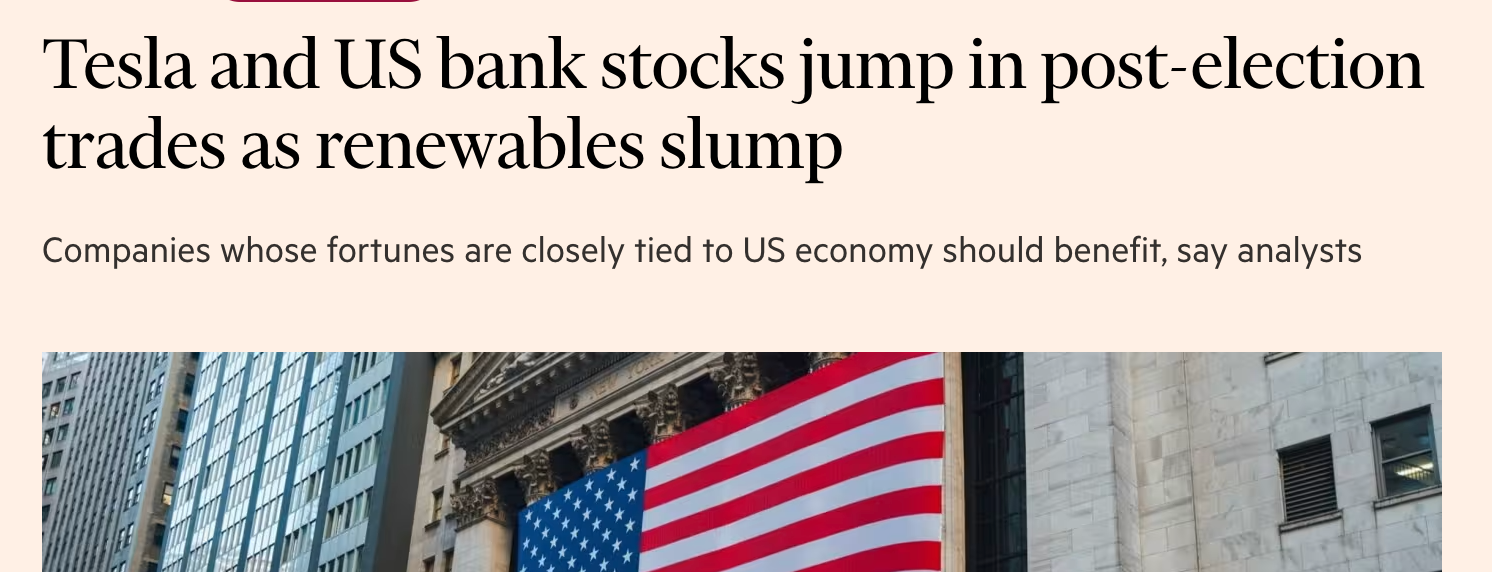

Let us investigate the statements in the Financial Times article from November 7.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import yfinance as yf
import datetime as dt

Define specific list of "winner" and "losers" stock tickers based on the classification in the Financial Times article.

In [ ]:
winner_stocks = ['JPM','MS','C','BAC','GS', 'WFC','BX', 'KKR',]
loser_stocks = ['FSLR','NEE','AMT','CCI','IRM','SWK','PEP','FE','MDLZ']

Download the historical daily closing prices for the selected stocks from Yahoo Finance for the specified period (2024-2025).


In [ ]:
df_winners = yf.download(winner_stocks,
                         start = "2024-01-01", end = "2025-01-01",
                         auto_adjust=True, progress=False)
df_winners = df_winners['Close']
df_losers = yf.download(loser_stocks,
                         start = "2024-01-01", end = "2025-01-01",
                        auto_adjust=True, progress=False)
df_losers = df_losers['Close']


Convert the raw prices into daily logarithmic returns to measure the percentage change and normalize the data.

In [ ]:
df_winners = df_winners.apply(np.log).diff(1)
df_losers = df_losers.apply(np.log).diff(1)

Locate the specific index of the event date in the data and define the integer ranges for the estimation and event windows.

In [ ]:
estimation_window = [-100,-11]
event_window = [-10,10]
event_date = dt.datetime(2024,11,6)

event_date_index = df_winners.index.tz_localize(None).get_loc(event_date)
est_window_index = range(event_date_index + estimation_window[0],
                         event_date_index + estimation_window[1]+1)

event_window_index = range(event_date_index + event_window[0],
                         event_date_index + event_window[1]+1)


Extract the data for the estimation period and calculate the expected mean returns (μ) to establish the baseline for the Constant Return Mode

In [ ]:
df_w_est_window = df_winners.iloc[est_window_index,:]
df_l_est_window = df_losers.iloc[est_window_index,:]

# constant return model
mu_winners = np.mean(df_w_est_window, axis = 0)
mu_losers = np.mean(df_l_est_window, axis = 0)


Compute the Abnormal Returns (AR) and aggregate them into Cumulative Abnormal Returns (CAR), while also calculating 95% confidence intervals to assess statistical significance

In [ ]:
# abnormal returns
df_w_event_window = df_winners.iloc[event_window_index,:]-mu_winners
df_l_event_window = df_losers.iloc[event_window_index,:]-mu_losers

std_w = df_w_event_window.std(axis = 1)
std_l = df_l_event_window.std(axis = 1)

horizon = np.arange(1,len(std_w)+1)

CAR_w = np.mean(df_w_event_window.cumsum(), axis = 1)
CAR_w_up = CAR_w + 1.96*std_w*np.sqrt(horizon)
CAR_w_low = CAR_w - 1.96*std_w*np.sqrt(horizon)
CAR_l = np.mean(df_l_event_window.cumsum(), axis = 1)
CAR_l_up = CAR_l + 1.96*std_l*np.sqrt(horizon)
CAR_l_low = CAR_l - 1.96*std_l*np.sqrt(horizon)

Plot the CAR trends for both "Winners" and "Losers" over the event timeline, shading the confidence intervals to visually determine if the market reaction was significant.

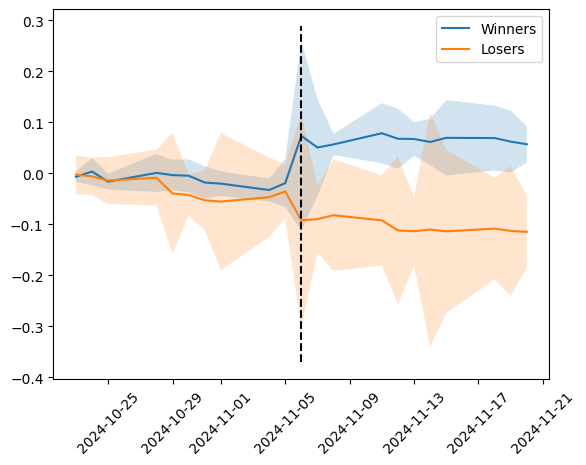

In [ ]:
event_timeline = df_winners.index[event_window_index]
plt.plot(event_timeline, CAR_w, event_timeline, CAR_l)
plt.fill_between(event_timeline, CAR_w_up, CAR_w_low, alpha=0.2, label="Confidence Interval")
plt.fill_between(event_timeline, CAR_l_up, CAR_l_low, alpha=0.2, label="Confidence Interval")
plt.plot([event_date, event_date],plt.ylim(),'--k')
plt.xticks(rotation=45)
plt.legend(['Winners','Losers'])

###Exercise
What would be an example of another event that affected two kind of firms differently? Check your event by creating an event study figure.